# Kesit İstatistik — Stokastik süreçler ve risk

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Markov zincirleri ve durağan dağılım

Bir durumdan diğerine geçiş uzun dönemi nasıl belirler?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Başlangıç etkisinin durağan dağılıma yaklaşmasını izle.

**Yorum sınırı:** Sabit geçiş matrisi ve uygun ergodiklik gerekir; her Markov zinciri tek durağan limite gitmez.

**Alıştırma:** İlk satırı [.9,.1] yap; uzun dönem ve yakınsama hızını karşılaştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'duragan': [0.5999999999999999, 0.40000000000000013], '35_adim': [0.600000000011642, 0.39999999998835867]}


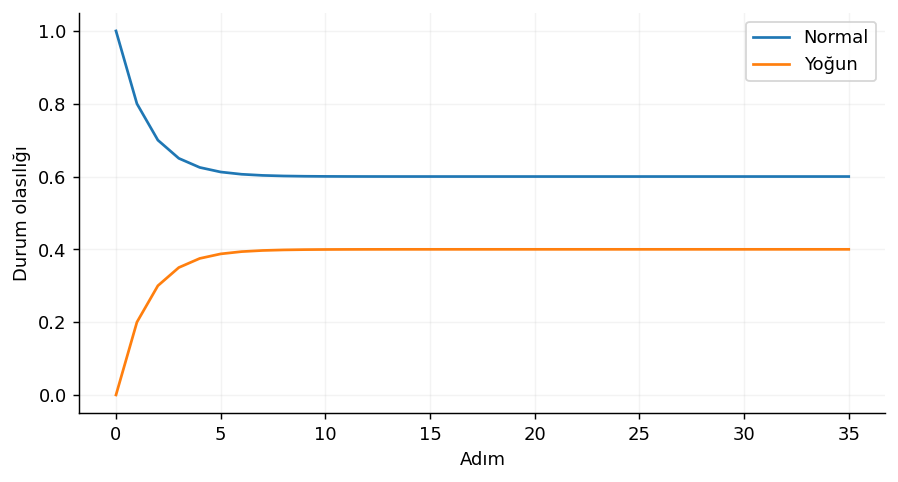

In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

P=np.array([[.8,.2],[.3,.7]]);dist=np.array([1.,0.]);history=[dist.copy()]
for t in range(35):dist=dist@P;history.append(dist.copy())
A=np.vstack([P.T-np.eye(2),np.ones(2)]);stationary=np.linalg.lstsq(A,[0,0,1],rcond=None)[0];assert np.allclose(stationary@P,stationary)
print({'duragan':stationary.tolist(),'35_adim':dist.tolist()});plt.plot(history);plt.xlabel('Adım');plt.ylabel('Durum olasılığı');plt.legend(['Normal','Yoğun'])

## Kuyruk teorisi ve Little yasası

Kullanımı yükseltmek beklemeyi ne kadar artırır?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** M/M/1 eğrisindeki doğrusal olmayan artışı oku.

**Yorum sınırı:** Poisson geliş, üstel hizmet, tek sunucu ve λ<μ varsayılır; W saat birimindedir.

**Alıştırma:** Hizmet hızını 10’dan 12’ye çıkar; aynı gelişte bekleme kazancını hesapla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'rho': 0.8, 'W_dakika': 30.0, 'L': 4.0, 'Little_kontrol': 4.0}


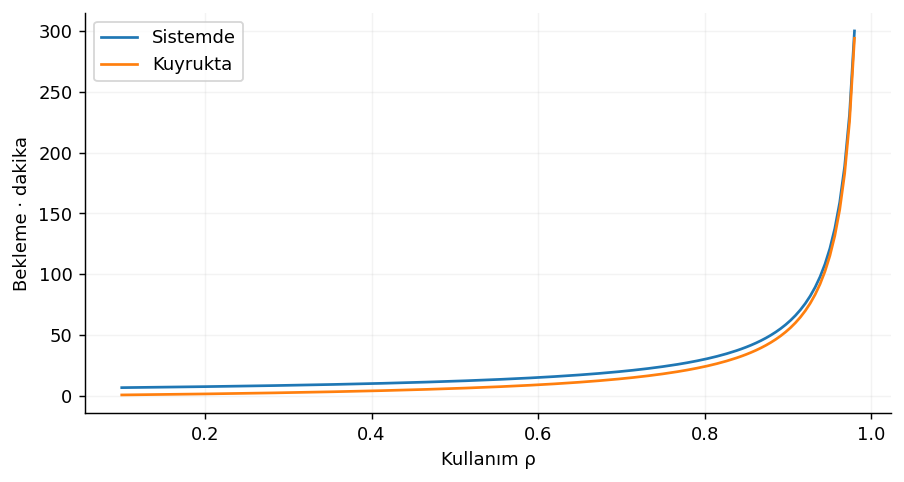

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

mu=10.;lam=np.linspace(1,9.8,150);W=1/(mu-lam);Wq=lam/(mu*(mu-lam));l=8.;print({'rho':l/mu,'W_dakika':60/(mu-l),'L':l/(mu-l),'Little_kontrol':l*1/(mu-l)})
plt.plot(lam/mu,60*W,label='Sistemde');plt.plot(lam/mu,60*Wq,label='Kuyrukta');plt.xlabel('Kullanım ρ');plt.ylabel('Bekleme · dakika');plt.legend()

## Uç değerler, VaR ve beklenen kuyruk kaybı

Ortalama kayıp yerine kuyruk riskini nasıl raporlarım?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** VaR eşiği ile eşiği aşan kayıpların ortalamasını ayır.

**Yorum sınırı:** Tarihsel/sentetik örneklem kuyruğu gelecekte garanti değildir; küçük kuyruk örneklemi kararsızdır.

**Alıştırma:** α=.95 yerine .99 kullan; kuyruktaki kayıt sayısını mutlaka raporla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'VaR': np.float64(40.333594072852094), 'ES': np.float64(66.48585914154746), 'kuyruk_n': 200}


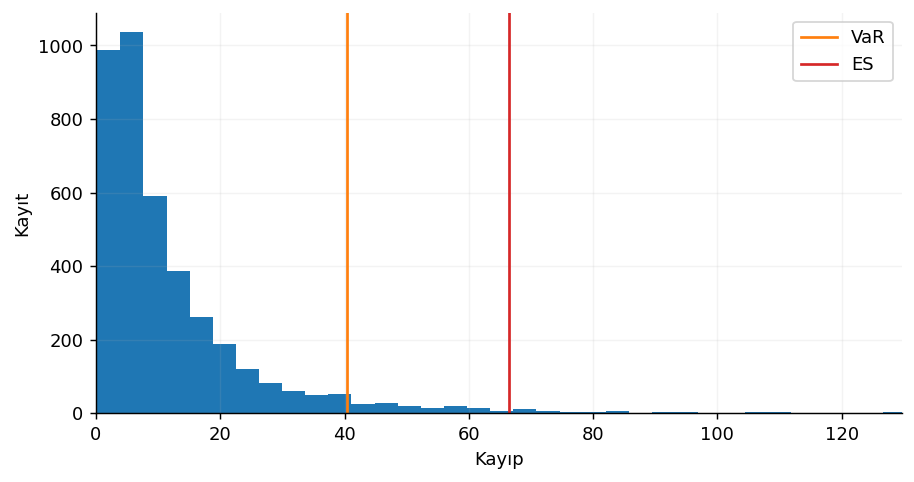

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

loss=rng.lognormal(2,1,4000);alpha=.95;var=np.quantile(loss,alpha);tail=loss[loss>=var];es=tail.mean();print({'VaR':var,'ES':es,'kuyruk_n':len(tail)})
plt.hist(loss,bins=80);plt.axvline(var,c='tab:orange',label='VaR');plt.axvline(es,c='tab:red',label='ES');plt.xlim(0,np.quantile(loss,.997));plt.xlabel('Kayıp');plt.ylabel('Kayıt');plt.legend()

## Entropi, KL ve dağılım karşılaştırması

Dağılım kaymasını tek bir ortalamayla görebilir miyim?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** P ve Q kategorilerinin paylarını KL yönüyle birlikte oku.

**Yorum sınırı:** KL asimetriktir ve Q sıfırken P pozitifse sonsuzdur; kategoriler aynı tanımlanmalı.

**Alıştırma:** Q’nun ilk payını .2’den .05’e indirip normalize et; iki KL yönünü karşılaştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'H_P_bit': np.float64(1.295461844238322), 'KL_P_Q_bit': np.float64(0.6264662506490408), 'KL_Q_P_bit': np.float64(0.6490224995673062)}


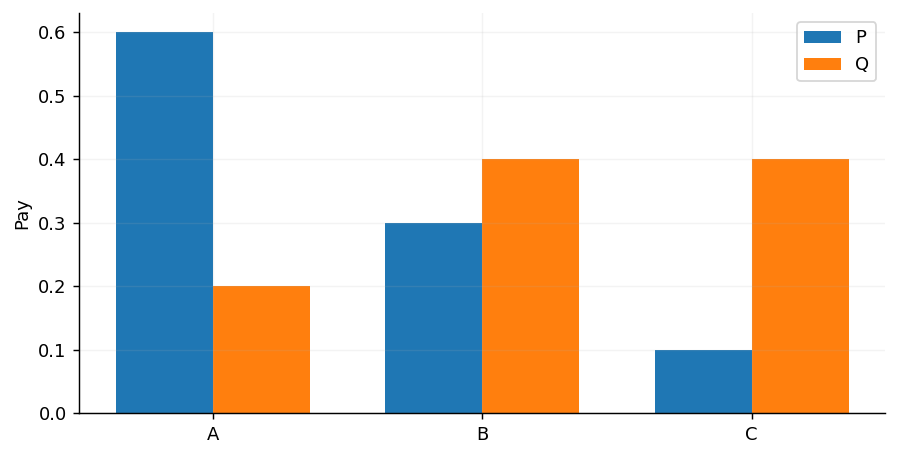

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

p=np.array([.6,.3,.1]);q=np.array([.2,.4,.4]);print({'H_P_bit':stats.entropy(p,base=2),'KL_P_Q_bit':stats.entropy(p,q,base=2),'KL_Q_P_bit':stats.entropy(q,p,base=2)})
x=np.arange(3);plt.bar(x-.18,p,.36,label='P');plt.bar(x+.18,q,.36,label='Q');plt.xticks(x,['A','B','C']);plt.ylabel('Pay');plt.legend()